In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.proportion import confint_proportions_2indep

print("All libraries imported successfully!")

All libraries imported successfully!


In [1]:
import seaborn as sns

# Load Titanic dataset
df = sns.load_dataset("titanic")

# Save a copy in the data folder
df.to_csv("../data/titanic.csv", index=False)

# Display first 5 rows
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


<h2> dataset information </h2>

In [2]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (891, 15)

Column Names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone

<h3> statical summary </h3>

In [3]:
df.describe(include="all")

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<h3> Missing values </h3>

In [4]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

age            177
embarked         2
deck           688
embark_town      2
dtype: int64

<h3> data cleaning </h3>

In [5]:
# Create a copy
data = df.copy()

# Fill missing age values with median
data["age"] = data["age"].fillna(data["age"].median())

# Fill missing embarked values with mode
data["embarked"] = data["embarked"].fillna(data["embarked"].mode()[0])

# Remove rows where essential variables are missing
data = data.dropna(subset=["sex", "survived"])

print("Missing values after cleaning:")
print(data[["sex", "survived", "age", "embarked"]].isnull().sum())

Missing values after cleaning:
sex         0
survived    0
age         0
embarked    0
dtype: int64


<h3> check target variables </he>

In [6]:
print("Gender distribution:")
print(data["sex"].value_counts())

print("\nSurvival distribution:")
print(data["survived"].value_counts())

Gender distribution:
sex
male      577
female    314
Name: count, dtype: int64

Survival distribution:
survived
0    549
1    342
Name: count, dtype: int64


<h3> survival rate by gender </he>

In [7]:
survival_by_gender = data.groupby("sex")["survived"].agg(
    ["count", "sum", "mean"]
)

survival_by_gender.columns = [
    "Total Passengers",
    "Survivors",
    "Survival Rate"
]

survival_by_gender["Survival Rate (%)"] = (
    survival_by_gender["Survival Rate"] * 100
)

survival_by_gender

,Total Passengers,Survivors,Survival Rate,Survival Rate (%)
sex,,,,
female,314,233,0.742038,74.203822
male,577,109,0.188908,18.890815


<h3> visualisation : survival count </he>

FileNotFoundError: [Errno 2] No such file or directory: '../visualizations/survival_by_gender.png'

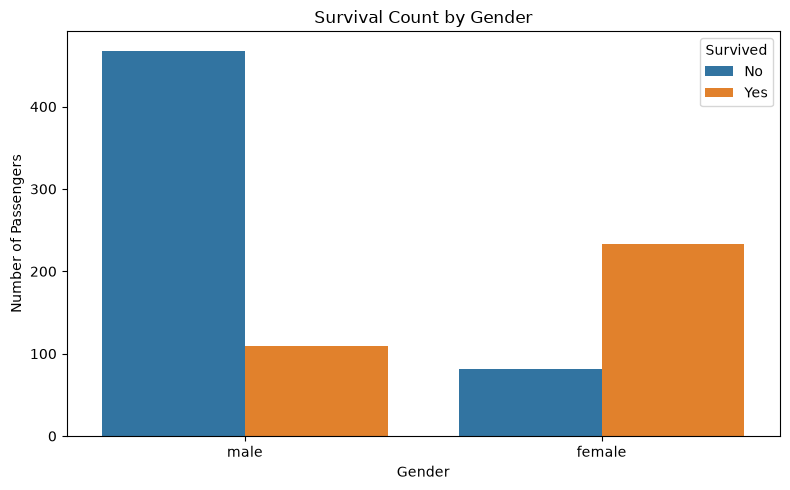

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x="sex",
    hue="survived"
)

plt.title("Survival Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.legend(
    title="Survived",
    labels=["No", "Yes"]
)

plt.tight_layout()
plt.savefig("../visualizations/survival_by_gender.png", dpi=300)
plt.show()

<h3> visualisation : survival rate </h3>

FileNotFoundError: [Errno 2] No such file or directory: '../visualizations/survival_rate_by_gender.png'

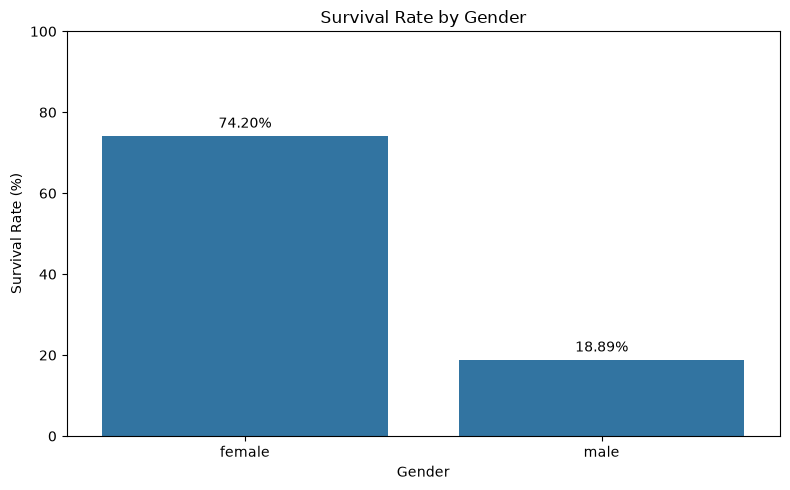

In [11]:
survival_rate = (
    data.groupby("sex")["survived"]
    .mean()
    .reset_index()
)

survival_rate["survived"] *= 100

plt.figure(figsize=(8, 5))

sns.barplot(
    data=survival_rate,
    x="sex",
    y="survived"
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")

plt.ylim(0, 100)

for i, value in enumerate(survival_rate["survived"]):
    plt.text(
        i,
        value + 2,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("../visualizations/survival_rate_by_gender.png", dpi=300)
plt.show()

<h3> Define hypothesis </h3>

In [12]:
print("Null Hypothesis (H0):")
print("There is no statistically significant association between gender and survival.")

print("\nAlternative Hypothesis (H1):")
print("There is a statistically significant association between gender and survival.")

print("\nSignificance Level: α = 0.05")

Null Hypothesis (H0):
There is no statistically significant association between gender and survival.

Alternative Hypothesis (H1):
There is a statistically significant association between gender and survival.

Significance Level: α = 0.05


<h3> contigency table </h3>

In [13]:
contingency_table = pd.crosstab(
    data["sex"],
    data["survived"]
)

print("Contingency Table:")
contingency_table

Contingency Table:


survived,0,1
sex,,
female,81,233
male,468,109


<h3> Chi square test </h3>

In [14]:
chi2, p_value, degrees_of_freedom, expected = chi2_contingency(
    contingency_table
)

print("Chi-Square Statistic:", chi2)
print("p-value:", p_value)
print("Degrees of Freedom:", degrees_of_freedom)

print("\nExpected Frequencies:")
print(expected)

Chi-Square Statistic: 260.71702016732104
p-value: 1.1973570627755645e-58
Degrees of Freedom: 1

Expected Frequencies:
[[193.47474747 120.52525253]
 [355.52525253 221.47474747]]


<h3> Interpret chi square test </h3>

In [15]:
alpha = 0.05

if p_value < alpha:
    print("Decision: Reject the Null Hypothesis.")
    print(
        "There is a statistically significant association "
        "between gender and survival."
    )
else:
    print("Decision: Fail to Reject the Null Hypothesis.")
    print(
        "There is not enough statistical evidence to establish "
        "an association between gender and survival."
    )

Decision: Reject the Null Hypothesis.
There is a statistically significant association between gender and survival.


<h3> Chi square heatmap </he>

FileNotFoundError: [Errno 2] No such file or directory: '../visualizations/contingency_heatmap.png'

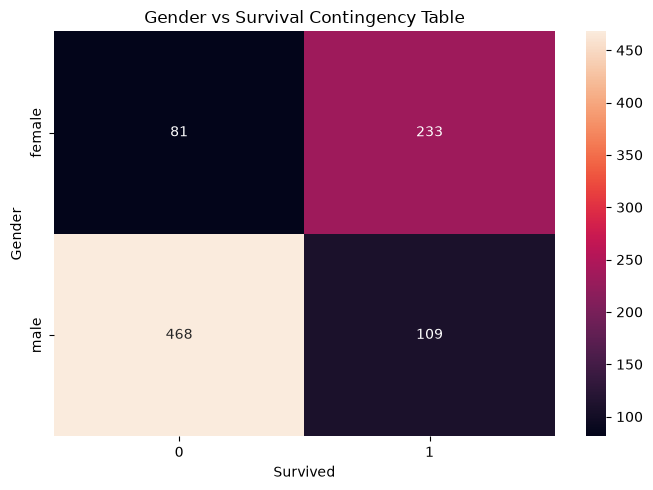

In [16]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    contingency_table,
    annot=True,
    fmt="d"
)

plt.title("Gender vs Survival Contingency Table")
plt.xlabel("Survived")
plt.ylabel("Gender")

plt.tight_layout()
plt.savefig("../visualizations/contingency_heatmap.png", dpi=300)
plt.show()

<h3> Survival Proportions </he>

In [17]:
male = data[data["sex"] == "male"]
female = data[data["sex"] == "female"]

male_survivors = male["survived"].sum()
female_survivors = female["survived"].sum()

male_total = len(male)
female_total = len(female)

male_rate = male_survivors / male_total
female_rate = female_survivors / female_total

print(f"Male survival rate: {male_rate:.4f}")
print(f"Female survival rate: {female_rate:.4f}")
print(f"Difference: {female_rate - male_rate:.4f}")

Male survival rate: 0.1889
Female survival rate: 0.7420
Difference: 0.5531


<h3> Two proportions : Z test </h3>

In [18]:
successes = np.array([
    female_survivors,
    male_survivors
])

observations = np.array([
    female_total,
    male_total
])

z_stat, p_value_prop = proportions_ztest(
    successes,
    observations
)

print("Z-statistic:", z_stat)
print("p-value:", p_value_prop)

Z-statistic: 16.218833930670097
p-value: 3.7117477701134797e-59


<h3> Interpret Z-test </h3>

In [19]:
if p_value_prop < alpha:
    print("Decision: Reject the Null Hypothesis.")
    print(
        "The difference between male and female survival "
        "proportions is statistically significant."
    )
else:
    print("Decision: Fail to Reject the Null Hypothesis.")
    print(
        "The difference between the two survival proportions "
        "is not statistically significant."
    )

Decision: Reject the Null Hypothesis.
The difference between male and female survival proportions is statistically significant.


<h3> 95% confidence interval </h3>

In [20]:
ci_low, ci_high = confint_proportions_2indep(
    female_survivors,
    female_total,
    male_survivors,
    male_total,
    method="wald"
)

print("95% Confidence Interval for the difference in survival proportions:")
print("Lower Bound:", ci_low)
print("Upper Bound:", ci_high)

95% Confidence Interval for the difference in survival proportions:
Lower Bound: 0.49514828626736046
Upper Bound: 0.6111118556924802


<h3> Confidence Interval in Percentage </h3>

In [21]:
print(
    f"95% Confidence Interval: "
    f"{ci_low * 100:.2f}% to {ci_high * 100:.2f}%"
)

print(
    f"Estimated difference in survival rates: "
    f"{(female_rate - male_rate) * 100:.2f} percentage points"
)

95% Confidence Interval: 49.51% to 61.11%
Estimated difference in survival rates: 55.31 percentage points


<h1> Additional Analysis </h1>

<h3> Survival by passenger class </h3>

In [22]:
class_survival = (
    data.groupby("class")["survived"]
    .mean()
    .reset_index()
)

class_survival["survived"] *= 100

class_survival

,class,survived
0,First,62.962963
1,Second,47.282609
2,Third,24.236253


<h3> Passenger class visualisation </h3>

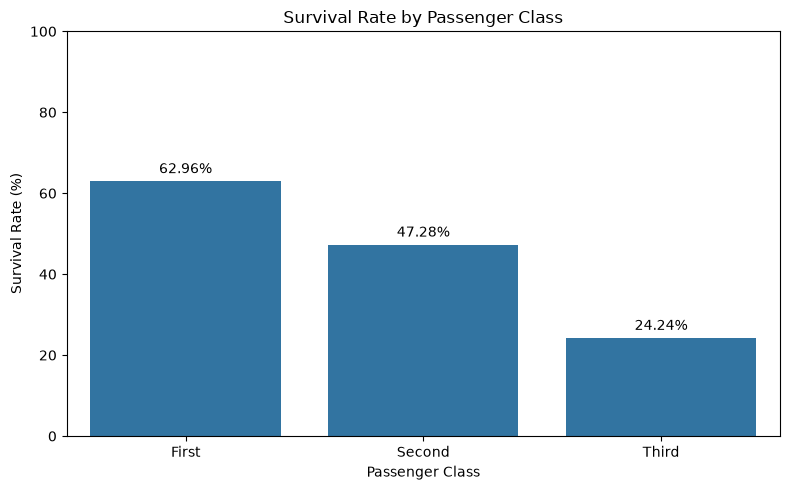

In [23]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=class_survival,
    x="class",
    y="survived"
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")

plt.ylim(0, 100)

for i, value in enumerate(class_survival["survived"]):
    plt.text(
        i,
        value + 2,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

<h3> Age Distribution </h3>

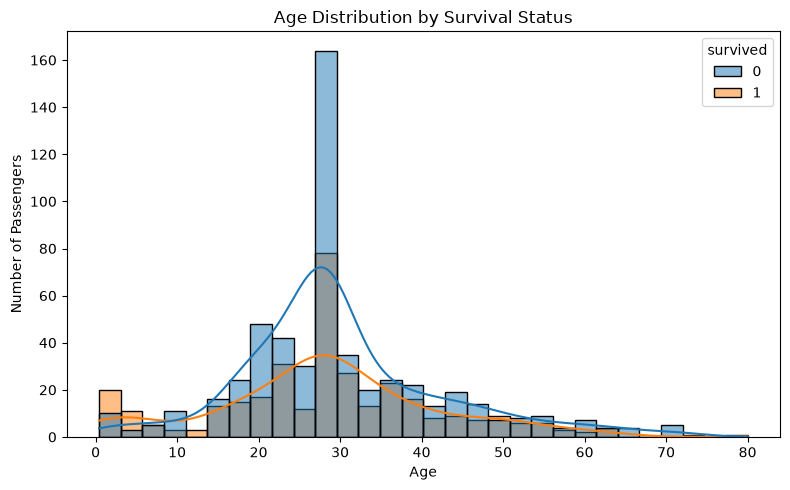

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=data,
    x="age",
    hue="survived",
    kde=True,
    bins=30
)

plt.title("Age Distribution by Survival Status")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

<h2> Final statical summary <h2>

In [25]:
results = pd.DataFrame({
    "Test": [
        "Chi-Square Test",
        "Two-Proportion Z-Test"
    ],
    "Statistic": [
        chi2,
        z_stat
    ],
    "p-value": [
        p_value,
        p_value_prop
    ],
    "Significance Level": [
        0.05,
        0.05
    ],
    "Result": [
        "Significant" if p_value < 0.05 else "Not Significant",
        "Significant" if p_value_prop < 0.05 else "Not Significant"
    ]
})

results

,Test,Statistic,p-value,Significance Level,Result
0,Chi-Square Test,260.717020,1.197357e-58,0.05,Significant
1,Two-Proportion Z-Test,16.218834,3.711748e-59,0.05,Significant


<h3> Save Results </h3>

In [27]:
results.to_csv(
    "../results/statistical_results.csv",
    index=False
)

with open("../results/statistical_results.txt", "w") as f:
    f.write("STATISTICAL ANALYSIS RESULTS\n")
    f.write("============================\n\n")
    
    f.write(f"Chi-Square Statistic: {chi2:.4f}\n")
    f.write(f"Chi-Square p-value: {p_value:.6f}\n")
    f.write(f"Degrees of Freedom: {degrees_of_freedom}\n\n")
    
    f.write(f"Z-statistic: {z_stat:.4f}\n")
    f.write(f"Z-test p-value: {p_value_prop:.6f}\n\n")
    
    f.write(
        f"95% CI for difference: "
        f"{ci_low:.4f} to {ci_high:.4f}\n"
    )

print("Results saved successfully!")

Results saved successfully!


<h1> Final Conclusions </h1>

In [28]:
print("=" * 60)
print("FINAL CONCLUSION")
print("=" * 60)

if p_value < 0.05:
    print(
        "The Chi-Square test produced a statistically significant result "
        "(p < 0.05). Therefore, the null hypothesis is rejected."
    )
    print(
        "The analysis provides statistical evidence of an association "
        "between passenger gender and survival status."
    )
else:
    print(
        "The Chi-Square test did not produce a statistically significant "
        "result (p >= 0.05). Therefore, the null hypothesis is not rejected."
    )

print(
    f"\nFemale survival rate: {female_rate * 100:.2f}%"
)

print(
    f"Male survival rate: {male_rate * 100:.2f}%"
)

print(
    f"\n95% CI for difference in proportions: "
    f"{ci_low * 100:.2f}% to {ci_high * 100:.2f}%"
)

print("\nAnalysis completed successfully.")

FINAL CONCLUSION
The Chi-Square test produced a statistically significant result (p < 0.05). Therefore, the null hypothesis is rejected.
The analysis provides statistical evidence of an association between passenger gender and survival status.

Female survival rate: 74.20%
Male survival rate: 18.89%

95% CI for difference in proportions: 49.51% to 61.11%

Analysis completed successfully.
